Call 1: setup and predictions

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Arc
from xgboost import XGBClassifier

meta = pd.read_csv('shots_meta.csv')
x_all = pd.read_csv('x_all.csv')

xgb_model = XGBClassifier()
xgb_model.load_model('xgb_model.json')
meta['p_xgb'] = xgb_model.predict_proba(x_all)[:, 1]

test = meta[meta['is_test']].copy()

In [2]:
def draw_court(ax, color="black", lw=1.2):
    # Create the various parts of an NBA basketball court
    ax.add_patch(Circle((0,0), 7.5, lw=lw, ec=color, fill=False))
    ax.add_patch(Rectangle((-30, -7.5), 60, -1, lw=lw, ec=color, fc=color))
    ax.add_patch(Rectangle((-80, -47.5), 160, 190, lw=lw, ec=color, fill=False))
    ax.add_patch(Rectangle((-60, -47.5), 120, 190, lw=lw, ec=color, fill=False))
    ax.add_patch(Arc((0, 142.5), 120, 120, theta1=0, theta2=180, lw=lw, ec=color, ls='dashed'))
    ax.add_patch(Arc((0, 142.5), 120, 120, theta1=180, theta2=360, lw=lw, ec=color))
    ax.add_patch(Arc((0,0), 80, 80, theta1=0, theta2=180, lw=lw, ec=color))
    ax.plot([-220, -220], [-47.5, 92.5], color=color, lw=lw)
    ax.plot([220, 220], [-47.5, 92.5], color=color, lw=lw)
    ax.add_patch(Arc((0, 0), 475, 475, theta1=22, theta2=158, lw=lw, ec=color))
    ax.set_xlim(-250, 250); ax.set_ylim(-50, 300)
    ax.set_aspect("equal"); ax.axis("off")

def hex_panel(ax, d, values, title, cmap, vmin, vmax, mincnt=15, gridsize=26):
    # Create a hexbin plot of the data
    hb = ax.hexbin(d["LOC_X"], d["LOC_Y"], C=values, reduce_C_function=np.mean, 
                   gridsize=gridsize, extent=(-250, 250, -50, 300), mincnt=mincnt,
                   cmap=cmap, vmin=vmin, vmax=vmax, linewidths=0.2)
    draw_court(ax)
    ax.set_title(title, fontsize=11)
    return hb


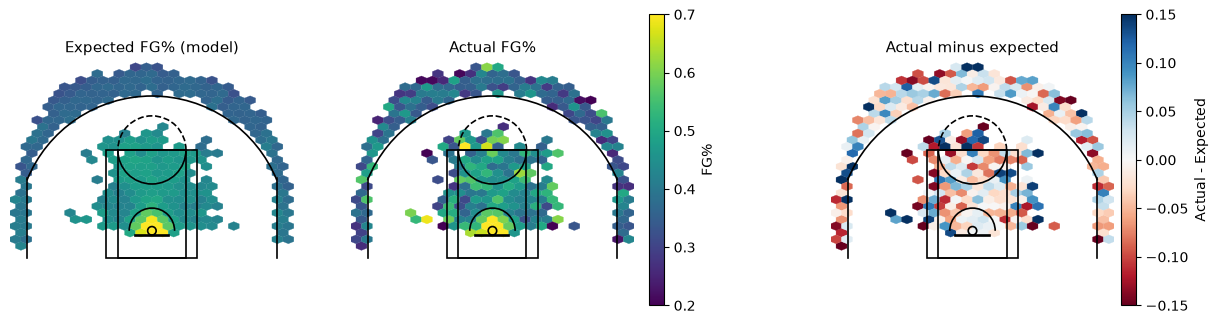

In [3]:
def court_figure(d, p_col="p_xgb", save="fig_court.png"):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
    hex_panel(axes[0], d, d[p_col], "Expected FG% (model)", "viridis", 0.2, 0.7)
    hb2 = hex_panel(axes[1], d, d["made"], "Actual FG%", "viridis", 0.2, 0.7)
    hb3 = hex_panel(axes[2], d, d["made"] - d[p_col], "Actual minus expected", "RdBu", -0.15, 0.15)
    fig.colorbar(hb2, ax=axes[:2], shrink=0.7, pad=0.02, label="FG%")
    fig.colorbar(hb3, ax=axes[2], shrink=0.7, pad=0.02, label="Actual - Expected")
    fig.savefig(save, dpi=300, bbox_inches="tight")

court_figure(test)
plt.show()

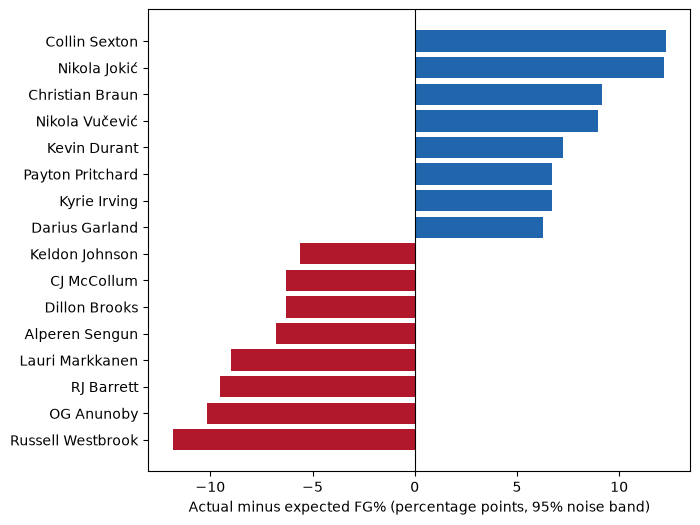

In [4]:
def player_table(d, p_col="p_xgb", min_shots=300):
    t = d.groupby(["PLAYER_ID", "PLAYER_NAME"]).agg(
        shots=("made", "size"), actual=("made", "mean"), expected=(p_col, "mean")).reset_index()
    var = (d[p_col] * (1 - d[p_col])).groupby(d["PLAYER_ID"]).sum()
    t["se"] = np.sqrt(t["PLAYER_ID"]).map(var) / t["shots"]
    t["diff"] = t["actual"] - t["expected"]
    t["beyond_noise"] = t["diff"].abs() > 1.96 * t["se"]
    return t[t["shots"] >= min_shots].sort_values("diff", ascending=False)

def player_figure(t, n=8, save="fig_players.png"):
    sel = pd.concat([t.head(n), t.tail(n)])
    fig, ax = plt.subplots(figsize=(7, 6))
    colors = np.where(sel["diff"] > 0, "#2166ac", "#b2182b")
    ax.barh(sel["PLAYER_NAME"], sel["diff"] * 100, xerr=1.96 * sel["se"] * 100,
            color=colors, capsize=2)
    ax.axvline(0, color="black", lw=0.8); ax.invert_yaxis()
    ax.set_xlabel("Actual minus expected FG% (percentage points, 95% noise band)")
    fig.savefig(save, dpi=300, bbox_inches="tight")

t = player_table(test, min_shots=100)
player_figure(t)

In [5]:
from sklearn.model_selection import GroupKFold, cross_val_predict

meta['p_oof'] = cross_val_predict(
    XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, random_state=42),
    x_all, meta['made'], groups=meta['GAME_ID'], cv=GroupKFold(5),
    method='predict_proba')[:, 1]

t = player_table(meta, p_col='p_oof', min_shots=300)

In [6]:
import joblib
lr_model = joblib.load('log_reg_baseline.pk1')
rf_model = joblib.load('random_forest.pkl')

meta['p_rf'] = rf_model.predict_proba(x_all)[:, 1]
meta['p_lr'] = lr_model.predict_proba(x_all)[:, 1]

meta.to_csv('shots_meta_preds.csv', index=False)
test = meta[meta['is_test']].copy()

Calibration table and figure

      bin  n_shots  mean_pred  actual_rate    gap  ci_low  ci_high  low_n  outside_ci
0.00-0.05       49      0.022        0.020  0.002   0.004    0.107   True       False
0.05-0.10       28      0.067        0.071 -0.004   0.020    0.226   True       False
0.10-0.15       29      0.129        0.241 -0.112   0.122    0.421   True       False
0.15-0.20       87      0.181        0.264 -0.084   0.183    0.366   True        True
0.20-0.25      208      0.228        0.327 -0.099   0.267    0.393  False        True
0.25-0.30      522      0.278        0.402 -0.124   0.361    0.445  False        True
0.30-0.35     1822      0.331        0.364 -0.033   0.343    0.387  False        True
0.35-0.40     5056      0.375        0.372  0.003   0.358    0.385  False       False
0.40-0.45     3258      0.424        0.410  0.013   0.394    0.427  False       False
0.45-0.50     3108      0.475        0.459  0.015   0.442    0.477  False       False
0.50-0.55     1807      0.522        0.481  0.040   0.

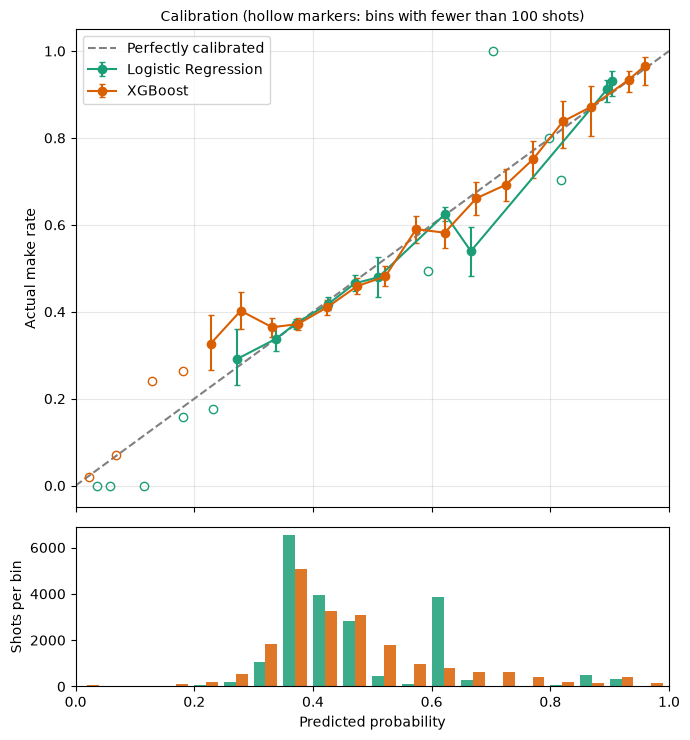

In [7]:
def wilson(k, n, z=1.96):
    phat = k / n
    denom = 1 + z**2 / n
    centre = (phat + z**2 / (2 * n)) / denom
    half = z * np.sqrt(phat * (1 - phat) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

def calibration_table(y, p, edges=None, min_n=100):
    y = np.asarray(y); p = np.asarray(p)
    if edges is None:
        edges = np.arange(0.0, 1.0001, 0.05)
    idx = np.clip(np.digitize(p, edges) - 1, 0, len(edges) - 2)
    rows = []
    for b in range(len(edges) - 1):
        m = idx == b
        n = int(m.sum())
        if n == 0:
            continue
        k = int(y[m].sum())
        lo, hi = wilson(k, n)
        mp = p[m].mean()
        rows.append({"bin": f"{edges[b]:.2f}-{edges[b+1]:.2f}", "n_shots": n,
                     "mean_pred": mp, "actual_rate": k / n, "gap": mp - k / n,
                     "ci_low": lo, "ci_high": hi,
                     "low_n": n < min_n,
                     "outside_ci": (mp < lo) or (mp > hi)})
    return pd.DataFrame(rows)

def calibration_figure(y, probs, edges=None, min_n=100, save="fig_calibration.png"):
    if edges is None:
        edges = np.arange(0.0, 1.0001, 0.05)
    fig, (ax, axh) = plt.subplots(2, 1, figsize=(7, 7.5), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 1]})
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfectly calibrated")
    colors = ["#1b9e77", "#d95f02", "#7570b3"]
    tables = {}
    for (name, p), c in zip(probs.items(), colors):
        t = calibration_table(y, p, edges, min_n)
        tables[name] = t
        ok, low = t[~t["low_n"]], t[t["low_n"]]
        err = np.vstack([ok["actual_rate"] - ok["ci_low"], ok["ci_high"] - ok["actual_rate"]])
        ax.errorbar(ok["mean_pred"], ok["actual_rate"], yerr=err, fmt="o-", color=c,
                    capsize=2, label=name)
        ax.plot(low["mean_pred"], low["actual_rate"], "o", mfc="none", color=c)
    ax.set_ylabel("Actual make rate")
    ax.set_title("Calibration (hollow markers: bins with fewer than %d shots)" % min_n, fontsize=10)
    ax.legend(); ax.grid(alpha=0.3)
    width = (edges[1] - edges[0]) / (len(probs) + 0.5)
    for i, ((name, p), c) in enumerate(zip(probs.items(), colors)):
        counts, _ = np.histogram(p, bins=edges)
        axh.bar(edges[:-1] + i * width, counts, width=width, align="edge", color=c, alpha=0.85)
    axh.set_xlabel("Predicted probability"); axh.set_ylabel("Shots per bin")
    axh.set_xlim(0, 1)
    fig.tight_layout()
    fig.savefig(save, dpi=300, bbox_inches="tight")
    return tables

tables = calibration_figure(test['made'], {"Logistic Regression": test['p_lr'],
                                           "XGBoost": test['p_xgb']})
print(tables["XGBoost"].round(3).to_string(index=False))
print(tables["Logistic Regression"].round(3).to_string(index=False))

Zone analysis

In [8]:
import numpy as np, pandas as pd
from sklearn.metrics import brier_score_loss

rows = []
for zone, d in test.groupby('SHOT_ZONE_BASIC'):
    if len(d) < 100:
        continue                      # skip tiny zones like Backcourt
    actual, pred = d['made'].mean(), d['p_xgb'].mean()
    brier = brier_score_loss(d['made'], d['p_xgb'])
    brier_zone_const = actual * (1 - actual)   # Brier if you predicted this zone's actual rate for every shot
    rows.append({'zone': zone, 'n': len(d), 'actual': actual, 'predicted': pred,
                 'gap': pred - actual, 'brier': brier,
                 'brier_zone_const': brier_zone_const,
                 'skill': 1 - brier / brier_zone_const})

zone_stats = pd.DataFrame(rows).round(3).sort_values('skill')
print(zone_stats.to_string(index=False))

# Poorly calibrated, well-populated bins from your calibration table
bad = tables['XGBoost']
print(bad[bad['outside_ci'] & ~bad['low_n']].round(3).to_string(index=False))

                 zone    n  actual  predicted    gap  brier  brier_zone_const  skill
        Left Corner 3  774   0.353      0.406  0.053  0.233             0.228 -0.019
    Above the Break 3 6720   0.364      0.359 -0.005  0.233             0.231 -0.006
            Mid-Range 2498   0.435      0.430 -0.005  0.247             0.246 -0.004
       Right Corner 3  726   0.380      0.403  0.023  0.237             0.236 -0.004
In The Paint (Non-RA) 4346   0.451      0.464  0.014  0.248             0.248  0.000
      Restricted Area 5120   0.665      0.664 -0.001  0.207             0.223  0.072
      bin  n_shots  mean_pred  actual_rate    gap  ci_low  ci_high  low_n  outside_ci
0.20-0.25      208      0.228        0.327 -0.099   0.267    0.393  False        True
0.25-0.30      522      0.278        0.402 -0.124   0.361    0.445  False        True
0.30-0.35     1822      0.331        0.364 -0.033   0.343    0.387  False        True
0.50-0.55     1807      0.522        0.481  0.040   0.458    